# 03 – Evaluation on the untouched test set (M3)

This is the **first and only time the test set is used**. Nothing here is tuned: the models, thresholds and
decision rule were all fixed in `02_train.ipynb` using train and validation.

Reported, for all three approaches on the same 200 test bins:
- **(a) Presence** of each catalogue product: precision, recall, F1.
- **(b) Quantity:** exact-match accuracy and mean absolute error.
- **(c) Orders:** PASS/FAIL accuracy and a confusion matrix, on test orders built from the test bins.
- **Failure analysis:** wrong predictions of the chosen model, with photos.

Runs on a laptop CPU in about a minute. Needs `models/` (from training) and `data/` (the data pack).

In [1]:
import os
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import joblib
from PIL import Image
from torchvision import models, transforms

ROOT = next(p for p in [Path("."), Path("..")] if (p / "app" / "smartbin.py").exists())
sys.path.insert(0, str((ROOT / "app").resolve()))
from smartbin import BinModel, check_order          # the SAME model loader and PASS/FAIL rule as the app

DATA, MODELS = ROOT / "data", ROOT / "models"
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
SEED = 42
PRETRAINED = os.environ.get("SBC_NO_PRETRAINED") != "1"   # only switched off for offline code tests

catalogue = pd.read_csv(DATA / "catalogue.csv", dtype={"asin": str})
CAT = list(catalogue["asin"])
NAMES = dict(zip(catalogue["asin"], catalogue["name"].str.slice(0, 40)))

test_df = pd.read_csv(DATA / "test" / "labels.csv", dtype={"bin_id": str})
test_df[CAT] = test_df[CAT].clip(upper=5)
Y = test_df[CAT].to_numpy()
images = [Image.open(DATA / "test" / "images" / f).convert("RGB") for f in test_df["image"]]
print(f"test bins: {len(test_df)} | products: {len(CAT)} | answers that are 0: {(Y == 0).mean():.0%}")

test bins: 200 | products: 10 | answers that are 0: 90%


## 1. Predictions from the three approaches

In [2]:
# C: fine-tuned ResNet-18 (the app's model)
model_C = BinModel(MODELS / "smartbin_resnet18.pt")
assert model_C.catalogue == CAT, "model and catalogue.csv disagree on the product list"
probs_C = np.concatenate([model_C.probabilities(images[i:i + 50]) for i in range(0, len(images), 50)])
pred_C = model_C.counts_from_probs(probs_C)

# B: frozen ImageNet ResNet-18 features + logistic regression
base_B = joblib.load(MODELS / "baseline_logreg.joblib")
feat_net = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if PRETRAINED else None)
feat_net.fc = nn.Identity()
feat_net.eval()
tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                         transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
with torch.no_grad():
    F = feat_net(torch.stack([tf(im) for im in images])).numpy()
probs_B = np.zeros((len(images), len(CAT), 6))
for k, clf in enumerate(base_B["models"]):
    probs_B[:, k, clf.classes_] = clf.predict_proba(F)
p_present_B = 1 - probs_B[:, :, 0]
pred_B = np.where(p_present_B >= np.asarray(base_B["thresholds"])[None, :], probs_B[:, :, 1:].argmax(2) + 1, 0)

# A: majority baseline
majority = json.load(open(MODELS / "baseline_majority.json"))["majority"]
pred_A = np.tile(majority, (len(images), 1))

PREDS = {"A majority": pred_A, "B features + LR": pred_B, "C fine-tuned ResNet-18": pred_C}
print("predictions ready")

c:\Users\sreec\smart-bin-classifier\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\sreec\smart-bin-classifier\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\sreec\smart-bin-classifier\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.6.1 when

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\sreec/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


predictions ready


## 2. (a) Presence and (b) quantity

In [3]:
def presence_table(y, p):
    rows = []
    for k, a in enumerate(CAT):
        t, q = y[:, k] > 0, p[:, k] > 0
        tp, fp, fn = int((t & q).sum()), int((~t & q).sum()), int((t & ~q).sum())
        prec = tp / (tp + fp) if tp + fp else 0.0
        rec = tp / (tp + fn) if tp + fn else 0.0
        rows.append({"product": NAMES[a], "support": int(t.sum()), "precision": prec, "recall": rec,
                     "f1": 2 * prec * rec / (prec + rec) if prec + rec else 0.0})
    return pd.DataFrame(rows)

summary = {}
for name, p in PREDS.items():
    per = presence_table(Y, p)
    present = Y > 0
    summary[name] = {
        "presence precision": per["precision"].mean(),
        "presence recall": per["recall"].mean(),
        "presence F1": per["f1"].mean(),
        "count exact (all answers)": (Y == p).mean(),
        "count exact (product present)": (Y == p)[present].mean(),
        "MAE (all answers)": np.abs(Y - p).mean(),
        "MAE (product present)": np.abs(Y - p)[present].mean(),
    }
summary = pd.DataFrame(summary).T
display(summary.round(3))

per_C = presence_table(Y, pred_C)
display(per_C.round(2))

,presence precision,presence recall,presence F1,count exact (all answers),count exact (product present),MAE (all answers),MAE (product present)
A majority,0.000,0.000,0.000,0.900,0.00,0.126,1.265
B features + LR,0.583,0.630,0.598,0.898,0.48,0.120,0.615
C fine-tuned ResNet-18,0.838,0.765,0.789,0.948,0.65,0.066,0.415


,product,support,precision,recall,f1
0,TaoTronics TT-AH002 30W Ultrasonic Humid,20,0.86,0.90,0.88
1,Fujifilm Instax Mini Instant Film (3 Twi,20,0.89,0.80,0.84
2,RTIC 30 oz. Tumbler,20,0.75,0.75,0.75
3,Pumpkin Pie Quest Bars 2 Pack Total of 2,20,0.94,0.80,0.86
4,Laser Lights Outdoor Starry Projector Re,20,1.00,0.70,0.82
5,"Best Microfiber Cleaning Cloth, Pack of",20,0.90,0.95,0.93
6,Lifetime Warranty FDA cleared OTC Health,20,0.79,0.75,0.77
7,3M 8511 Particulate N95 Respirator with,20,0.81,0.65,0.72
8,"UP2 by Jawbone Activity + Sleep Tracker,",20,0.82,0.45,0.58
9,"AuYou Wi-Fi Smart Outlet Switch, 5 Outle",20,0.62,0.90,0.73


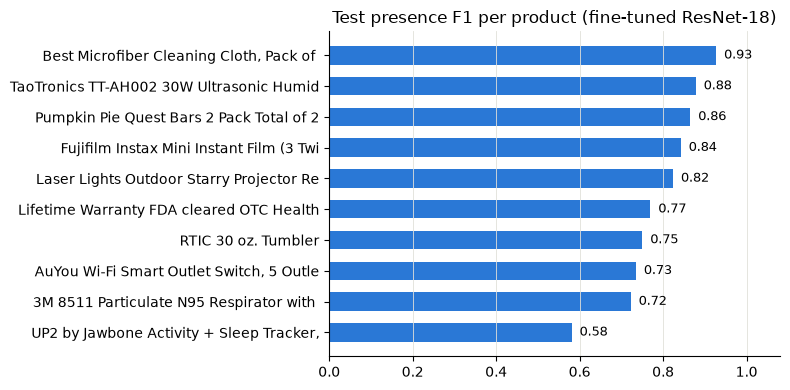

found quantity,0,1,2,3
true quantity,,,,
0,0,22,7,4
1,39,109,8,1
2,6,9,19,0
3,2,1,3,2
4,0,0,1,0


In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
s = per_C.sort_values("f1")
bars = ax.barh(s["product"], s["f1"], color="#2a78d6", height=0.6)
for b in bars:
    ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f"  {b.get_width():.2f}", va="center", fontsize=9)
ax.set_xlim(0, 1.08)
ax.set_title("Test presence F1 per product (fine-tuned ResNet-18)")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", color="#e1e0d9", lw=0.6)
plt.tight_layout(); plt.savefig(RESULTS / "test_f1_per_product.png", dpi=120); plt.show()

# Counting: true vs found quantity, only where the product is really present or was predicted present
mask = (Y > 0) | (pred_C > 0)
cm_q = pd.crosstab(pd.Series(Y[mask], name="true quantity"), pd.Series(pred_C[mask], name="found quantity"))
display(cm_q)

## 3. (c) Orders: PASS / FAIL

**How the test orders were built** (2 per test bin, 400 in total, seed 42):
- **PASS order:** every catalogue product in the bin, at its true quantity.
- **FAIL order:** the PASS order made impossible in one of two ways, chosen at random:
  - *add an absent item:* one catalogue product that is not in the bin, quantity 1;
  - *raise a quantity:* one ordered item asks for one more unit than the bin holds
    (if that would exceed 5, an absent item is added instead).

The true answer comes from the test labels; the predicted answer applies the app's rule (`check_order`) to the
model's found quantities. Raising a quantity by one is the hardest case, because the model must count exactly.

In [5]:
rng = np.random.default_rng(SEED)
orders = []
for i, row in test_df.iterrows():
    in_bin = {a: int(row[a]) for a in CAT if row[a] > 0}
    absent = [a for a in CAT if row[a] == 0]
    orders.append({"bin": i, "order": dict(in_bin), "truth": "PASS", "kind": "true contents"})
    fail, kind = dict(in_bin), "raise a quantity"
    target = rng.choice(list(in_bin))
    if rng.random() < 0.5 and in_bin[target] < 5:
        fail[target] = in_bin[target] + 1
    else:
        fail[rng.choice(absent)] = 1
        kind = "add an absent item"
    orders.append({"bin": i, "order": fail, "truth": "FAIL", "kind": kind})
orders = pd.DataFrame(orders)

# sanity: the true answer of every order agrees with the rule applied to the true quantities
true_found = [{a: int(test_df.loc[b, a]) for a in CAT} for b in orders["bin"]]
assert all(check_order(o, f)["result"] == t for o, f, t in zip(orders["order"], true_found, orders["truth"]))
print(orders["truth"].value_counts().to_dict(), "|", orders.loc[orders["truth"] == "FAIL", "kind"].value_counts().to_dict())

order_rows = {}
for name, p in PREDS.items():
    found = [{a: int(p[b, k]) for k, a in enumerate(CAT)} for b in orders["bin"]]
    orders[name] = [check_order(o, f)["result"] for o, f in zip(orders["order"], found)]
    t, q = orders["truth"], orders[name]
    order_rows[name] = {
        "order accuracy": (t == q).mean(),
        "bad orders caught (FAIL recall)": ((t == "FAIL") & (q == "FAIL")).sum() / (t == "FAIL").sum(),
        "good orders passed (PASS recall)": ((t == "PASS") & (q == "PASS")).sum() / (t == "PASS").sum(),
        "wrong PASS (bad order shipped)": int(((t == "FAIL") & (q == "PASS")).sum()),
        "wrong FAIL (good order re-checked)": int(((t == "PASS") & (q == "FAIL")).sum()),
    }
order_summary = pd.DataFrame(order_rows).T
display(order_summary.round(3))

{'PASS': 200, 'FAIL': 200} | {'raise a quantity': 102, 'add an absent item': 98}


,order accuracy,bad orders caught (FAIL recall),good orders passed (PASS recall),wrong PASS (bad order shipped),wrong FAIL (good order re-checked)
A majority,0.500,1.000,0.000,0.0,200.0
B features + LR,0.748,0.960,0.535,8.0,93.0
C fine-tuned ResNet-18,0.830,0.965,0.695,7.0,61.0


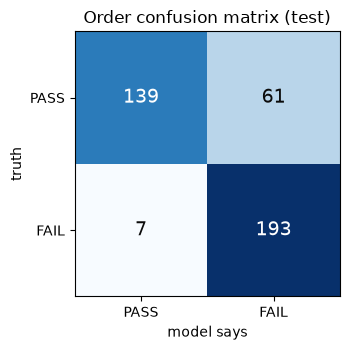

Bad orders caught, by how they were made: {'add an absent item': 0.99, 'raise a quantity': 0.94}


In [6]:
NAME = "C fine-tuned ResNet-18"
cm = pd.crosstab(orders["truth"], orders[NAME]).reindex(index=["PASS", "FAIL"], columns=["PASS", "FAIL"], fill_value=0)
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(cm.to_numpy(), cmap="Blues")
for (r, c), v in np.ndenumerate(cm.to_numpy()):
    ax.text(c, r, str(v), ha="center", va="center", fontsize=14,
            color="white" if v > cm.to_numpy().max() / 2 else "#0b0b0b")
ax.set_xticks([0, 1], ["PASS", "FAIL"]); ax.set_yticks([0, 1], ["PASS", "FAIL"])
ax.set_xlabel("model says"); ax.set_ylabel("truth"); ax.grid(False)
ax.set_title("Order confusion matrix (test)")
plt.tight_layout(); plt.savefig(RESULTS / "order_confusion_matrix.png", dpi=120); plt.show()

by_kind = orders[orders["truth"] == "FAIL"].groupby("kind")[NAME].apply(lambda s: (s == "FAIL").mean())
print("Bad orders caught, by how they were made:", by_kind.round(2).to_dict())

### Which metric matters most for a warehouse?

A **wrong PASS** means a bin that does not hold the order is approved: the wrong or incomplete parcel ships,
and the customer complaint, refund and return cost far more than a few seconds of a worker re-checking a bin.
A **wrong FAIL** only costs that re-check.

So the most important number is **how many bad orders are caught (FAIL recall)**, read together with the
wrong-FAIL count so the system is not useless. The majority baseline shows why both are needed: it says
"absent" for everything, so it FAILs every order – it catches 100% of bad orders but also rejects every good one.

## 4. Failure analysis (fine-tuned ResNet-18)

Wrong product-level predictions, in three kinds: **missed** (present but predicted 0), **false alarm**
(absent but predicted present) and **wrong count** (present, wrong number). For each, the most confident
mistakes are shown, with facts that help explain them: bin total units, units of non-catalogue products, and
photo sharpness. Look at each photo and write your explanation in the table below.

wrong product-level answers: {'missed': 47, 'false alarm': 33, 'wrong count': 23}


,bin_id,product,kind,true,found,confidence,bin total units,non-catalogue units,sharpness pct
case 1,148353,3M 8511 Particulate N95 Respirator with,false alarm,0,1,1.00,5,4,13
case 2,323801,3M 8511 Particulate N95 Respirator with,false alarm,0,1,1.00,2,1,26
case 3,77311,Fujifilm Instax Mini Instant Film (3 Twi,missed,1,0,1.00,3,2,26
case 4,109724,Fujifilm Instax Mini Instant Film (3 Twi,missed,1,0,1.00,3,2,61
case 5,356015,"Best Microfiber Cleaning Cloth, Pack of",wrong count,3,2,0.97,4,1,76
case 6,142779,Lifetime Warranty FDA cleared OTC Health,wrong count,4,2,0.97,4,0,4


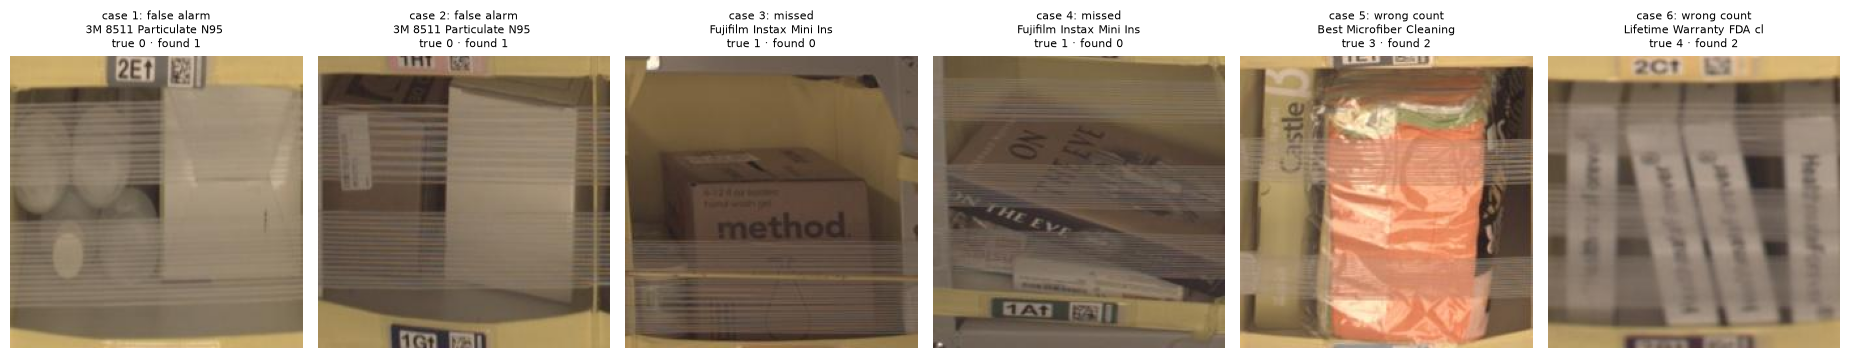

In [7]:
def sharpness(im):
    g = np.asarray(im.convert("L"), dtype=np.float32)
    return float((-4 * g[1:-1, 1:-1] + g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:]).var())

sharp = np.array([sharpness(im) for im in images])
p_present = 1 - probs_C[:, :, 0]
wrong = []
for b in range(len(images)):
    for k, a in enumerate(CAT):
        t, q = Y[b, k], pred_C[b, k]
        if t == q:
            continue
        kind = "missed" if q == 0 else "false alarm" if t == 0 else "wrong count"
        # how sure the model was of its wrong answer
        conf = probs_C[b, k, 0] if kind == "missed" else p_present[b, k] if kind == "false alarm" else probs_C[b, k, q]
        wrong.append({"bin_id": test_df.loc[b, "bin_id"], "b": b, "product": NAMES[a], "kind": kind,
                      "true": int(t), "found": int(q), "confidence": float(conf),
                      "bin total units": int(test_df.loc[b, "total_units"]),
                      "non-catalogue units": int(test_df.loc[b, "total_units"] - Y[b].sum()),
                      "sharpness pct": int((sharp < sharp[b]).mean() * 100)})
wrong = pd.DataFrame(wrong)
print("wrong product-level answers:", wrong["kind"].value_counts().to_dict())

cases = (wrong.sort_values("confidence", ascending=False).groupby("kind").head(2)
         .sort_values("kind").reset_index(drop=True))
cases.index = [f"case {i + 1}" for i in range(len(cases))]
display(cases.drop(columns="b").round(2))

fig, axes = plt.subplots(1, len(cases), figsize=(3.1 * len(cases), 3.6))
for ax, (cid, r) in zip(np.atleast_1d(axes), cases.iterrows()):
    ax.imshow(images[r["b"]]); ax.axis("off")
    ax.set_title(f"{cid}: {r['kind']}\n{r['product'][:24]}\ntrue {r['true']} · found {r['found']}", fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS / "failure_cases.png", dpi=120); plt.show()

**Explanation of each case** (from looking at the photos above and the facts in the table):

| Case | What went wrong | Why I think it happened | What I would do about it |
|---|---|---|---|
| case 1 (bin 148353) | N95 respirator: recorded 0, found 1, with full confidence | The photo shows white cup-shaped items behind tape that look like N95 masks. Either they are look-alike products, or the bin really holds respirators that the record misses (label noise). The photo is also blurry (13th sharpness percentile) and the bin is crowded (4 non-catalogue units). | Treat confident disagreements as candidates for a human audit of the record; if the label is right, add more look-alike white items as negative examples. |
| case 2 (bin 323801) | N95 respirator: recorded 0, found 1 | A plain white box fills the bin, very similar to the N95 10-pack box. The model has learned "large white box" rather than the product itself. | Hard-negative training: more bins with plain white boxes that are *not* the respirator. |
| case 3 (bin 77311) | Instax film: recorded 1, found 0 | A large "method" box covers most of the bin; the film pack is not visible in the photo. A front photo cannot show what is behind another item. | Accept as a limit of a single front photo, or add a second camera angle; flag bins with large occluding items for a manual check. |
| case 4 (bin 109724) | Instax film: recorded 1, found 0 | A book and tape stripes cover the bin; the film is a small flat pack, possibly under the book. At 224×224 pixels a small item is only a few pixels. | Use higher-resolution photos (or crops) so small items keep their detail. |
| case 5 (bin 356015) | Microfiber cloths: recorded 3, found 2 | The packs are stacked flat on top of each other, so from the front they look like fewer units. The photo is sharp (76th percentile), so this is occlusion, not blur. | Counting from one front view is unreliable for stacked items; a side or top view, or a count-aware loss that penalises being off by more, would help. |
| case 6 (bin 142779) | TENS unit: recorded 4, found 2 | Four identical boxes stand side by side behind heavy tape, and the photo is among the blurriest (4th percentile), so neighbouring boxes merge. | Check photo quality before validating (ask for a re-photo when sharpness is very low); add more multi-unit training examples. |

**Patterns across the mistakes**
- The model is often **confidently wrong** (confidence 0.97–1.00 above). That matches the overfitting seen in training
  (train loss near 0). Calibrating the probabilities (for example temperature scaling on validation) would let the app
  send uncertain bins to a human instead of guessing.
- Of the 7 bad orders the model would have shipped, **6 were "raise a quantity" orders**: the model over-counted by one.
  The costly error is therefore over-counting, not missing products. A production version should ask for a human check
  when the ordered quantity is above 1 and the count confidence is low.


In [8]:
# Order-level mistakes: bad orders the model passed (the costly kind)
shipped = orders[(orders["truth"] == "FAIL") & (orders[NAME] == "PASS")]
print(f"bad orders the model would have shipped: {len(shipped)}")
display(shipped.assign(bin_id=test_df.loc[shipped["bin"], "bin_id"].to_numpy())[["bin_id", "kind", "order"]].head(10))

bad orders the model would have shipped: 7


,bin_id,kind,order
57,149379,raise a quantity,{'B00O4OR4GQ': 2}
87,183936,add an absent item,"{'B013UJS35G': 1, 'B00O7CM12W': 1}"
107,20837,raise a quantity,{'B015QWHXWE': 2}
135,259907,raise a quantity,{'B01DV2OJYG': 2}
137,260269,raise a quantity,{'B01DV2OJYG': 2}
181,30252,raise a quantity,{'B00O4OR4GQ': 2}
313,467017,raise a quantity,{'B01FZ0WP3E': 2}


## 5. Save the test results

In [9]:
results = {
    "product_level": summary.round(4).to_dict(orient="index"),
    "order_level": order_summary.round(4).to_dict(orient="index"),
    "per_product_C": per_C.round(4).to_dict(orient="records"),
    "n_test_bins": len(test_df), "n_orders": len(orders),
}
json.dump(results, open(RESULTS / "test_metrics.json", "w"), indent=1, default=float)
orders.assign(order=orders["order"].map(json.dumps)).to_csv(RESULTS / "test_orders.csv", index=False)
wrong.drop(columns="b").to_csv(RESULTS / "test_wrong_predictions.csv", index=False)
print("saved:", sorted(p.name for p in RESULTS.iterdir()))

saved: ['failure_cases.png', 'order_confusion_matrix.png', 'test_f1_per_product.png', 'test_metrics.json', 'test_orders.csv', 'test_wrong_predictions.csv']
